# Laboratorio 11 · Guía 2 — Regularización: Ridge, Lasso y Elastic Net para Exposiciones Sectoriales y Volatilidad

**Curso:** Minería de Datos (DM + AIAP) · FISI · UNMSM · Semestre 2026-II · **Semana 12 del sílabo (Tema 12: Modelos de Regresión)**
**Docente:** Prof. Mg. Ing. Ernesto D. Cancho-Rodríguez, MBA (GWU)

**Fase CRISP-DM:** Preparación de los datos · Modelado · Evaluación.

**Pregunta de negocio:** cuando los regresores están **correlacionados** (los 11 **sectores** del S&P 500 se mueven juntos) los coeficientes de **MCO** se vuelven **inestables**. ¿A qué **sectores** está realmente expuesta una acción? ¿Y cuántas de las **65 variables** que un analista inventa para predecir el **riesgo** de la próxima semana sirven de verdad? **Ridge**, **Lasso** y **Elastic Net** responden ambas preguntas **encogiendo** o **anulando** coeficientes.

**Estructura:** Parte I, qué es una **penalización** · Parte II, **laboratorio de contraste sintético** (**Mundo 2**): colinealidad y selección de variables · Parte III, **exposiciones sectoriales** de 5 acciones (**Mundo 3**) · Parte IV, **pronóstico de la volatilidad** de SPY con 65 variables y validación cronológica (**Mundo 3**).

> **Enfoque didáctico:** cada paso en su propia celda con sus `print`. Semilla `SEMILLA = 2026`. Precios hasta el 11-nov-2026.

# PARTE I — Qué Hace una Penalización

## 1. Librerías, Semilla y Datos

**Ridge** minimiza **SCR + α·Σβⱼ²** (norma L2: encoge todos los coeficientes, nunca los anula). **Lasso** minimiza **SCR + α·Σ|βⱼ|** (norma L1: anula coeficientes, selecciona variables). **Elastic Net** combina ambas: **α·[ρ·Σ|βⱼ| + (1 − ρ)/2·Σβⱼ²]**. Como la penalización depende de la **escala** de cada variable, siempre se **estandariza** dentro de un **Pipeline** (ajustado solo con entrenamiento).

In [1]:
# Librerías del laboratorio
import warnings

warnings.filterwarnings("ignore")
import numpy as np  # cálculo numérico
import pandas as pd  # tablas
import matplotlib.pyplot as plt  # gráficos
import yfinance as yf  # precios de Yahoo Finance
import sklearn, statsmodels.api as sm
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, lasso_path
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, KFold
from sklearn.metrics import mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

SEMILLA = 2026
rng = np.random.default_rng(SEMILLA)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 110
print(
    "scikit-learn",
    sklearn.__version__,
    "| pandas",
    pd.__version__,
    "| NumPy",
    np.__version__,
)

scikit-learn 1.3.1 | pandas 2.2.3 | NumPy 1.26.4


In [2]:
# Precios de cierre ajustado de 28 activos (Yahoo Finance). Plan B: CSV de respaldo del curso (carpeta D03)
TICKERS = [
    "SPY",
    "QQQ",
    "XLK",
    "XLF",
    "XLE",
    "XLV",
    "XLY",
    "XLP",
    "XLI",
    "XLU",
    "XLB",
    "XLRE",
    "XLC",
    "GLD",
    "TLT",
    "AAPL",
    "MSFT",
    "JPM",
    "XOM",
    "CAT",
    "KO",
    "PFE",
    "BVN",
    "FSM",
    "SCCO",
    "BHP",
    "B",
    "^VIX",
]
ARCH = "26.11.12.cierres_ajustados_28_activos_2010-01-04_2026-11-11.csv"
try:
    precios = yf.download(
        TICKERS, start="2010-01-01", end="2026-11-12", auto_adjust=True, progress=False
    )["Close"].reindex(columns=TICKERS)
except Exception as e:
    precios = pd.DataFrame()
    print("Falló la descarga de Yahoo Finance:", e)
if precios.empty or precios["SPY"].notna().sum() < 4000:
    precios = pd.read_csv(
        ARCH, index_col=0, parse_dates=True
    )  # súbalo a Colab si Yahoo no responde
    print("Se usó el CSV de respaldo:", ARCH)
precios.index = pd.to_datetime(precios.index)
print(
    "Dimensiones:",
    precios.shape,
    "| desde",
    precios.index.min().date(),
    "hasta",
    precios.index.max().date(),
)
print(
    "Días con precio de SPY:",
    int(precios["SPY"].notna().sum()),
    "| último cierre de SPY:",
    round(float(precios["SPY"].iloc[-1]), 2),
)

Dimensiones: (4243, 28) | desde 2010-01-04 hasta 2026-11-11
Días con precio de SPY: 4241 | último cierre de SPY: 759.81


In [3]:
# Precios OHLCV (apertura, máximo, mínimo, cierre, volumen) ajustados de SPY. Plan B: CSV de respaldo (D03)
ARCH_SPY = "26.11.12.SPY_OHLCV_ajustado_2010-01-04_2026-11-11.csv"
try:
    spy = yf.download(
        "SPY", start="2010-01-01", end="2026-11-12", auto_adjust=True, progress=False
    )
    spy.columns = [c[0] if isinstance(c, tuple) else c for c in spy.columns]
    spy = spy[["Open", "High", "Low", "Close", "Volume"]]
except Exception as e:
    spy = pd.DataFrame()
    print("Falló la descarga de Yahoo Finance:", e)
if spy.empty or len(spy) < 4000:
    spy = pd.read_csv(ARCH_SPY, index_col=0, parse_dates=True)
    print("Se usó el CSV de respaldo:", ARCH_SPY)
spy.index = pd.to_datetime(spy.index)
print(
    "SPY OHLCV:",
    spy.shape,
    "| desde",
    spy.index.min().date(),
    "hasta",
    spy.index.max().date(),
)
print(spy.tail(3).round(2))

SPY OHLCV: (4241, 5) | desde 2010-01-04 hasta 2026-11-11
              Open    High     Low   Close    Volume
Date                                                
2026-11-09  741.95  755.42  741.03  752.69  50281200
2026-11-10  747.94  752.14  744.86  749.92  40698600
2026-11-11  756.80  762.51  754.90  759.81  38854000


In [4]:
# Nombres de los activos
NOMBRES = {
    "SPY": "S&P 500 (ETF)",
    "QQQ": "Nasdaq-100 (ETF)",
    "XLK": "Tecnología",
    "XLF": "Finanzas",
    "XLE": "Energía",
    "XLV": "Salud",
    "XLY": "Consumo discrecional",
    "XLP": "Consumo básico",
    "XLI": "Industriales",
    "XLU": "Servicios públicos",
    "XLB": "Materiales",
    "XLRE": "Inmobiliario",
    "XLC": "Comunicaciones",
    "GLD": "Oro",
    "TLT": "Bonos del Tesoro 20+",
    "AAPL": "Apple",
    "MSFT": "Microsoft",
    "JPM": "JPMorgan",
    "XOM": "ExxonMobil",
    "CAT": "Caterpillar",
    "KO": "Coca-Cola",
    "PFE": "Pfizer",
    "BVN": "Buenaventura (Perú)",
    "FSM": "Fortuna Mining",
    "SCCO": "Southern Copper",
    "BHP": "BHP",
    "B": "Barrick Mining",
    "^VIX": "Índice VIX",
}

## 2. El Efecto de α sobre un Coeficiente (Ilustración)

> **Observación:** datos **sintéticos** mínimos (una sola variable) para ver qué hace cada penalización al crecer **α**.

In [5]:
# Una variable con pendiente verdadera 2: coeficiente de MCO, Ridge y Lasso según alpha
x1 = rng.normal(size=100)
y1 = 2 * x1 + rng.normal(scale=1.0, size=100)
alphas_demo = [0, 0.1, 0.5, 1, 2, 5, 10, 50]
filas = []
for a in alphas_demo:
    b_r = (
        Ridge(alpha=a).fit(x1.reshape(-1, 1), y1).coef_[0]
        if a > 0
        else LinearRegression().fit(x1.reshape(-1, 1), y1).coef_[0]
    )
    b_l = Lasso(alpha=a).fit(x1.reshape(-1, 1), y1).coef_[0] if a > 0 else b_r
    filas.append([a, b_r, b_l])
print(
    pd.DataFrame(filas, columns=["alpha", "coef_Ridge", "coef_Lasso"])
    .round(4)
    .to_string(index=False)
)
print("Ridge encoge gradualmente; Lasso llega a CERO exacto (selección de variables)")

 alpha  coef_Ridge  coef_Lasso
   0.0      1.8995      1.8995
   0.1      1.8977      1.8031
   0.5      1.8904      1.4175
   1.0      1.8813      0.9355
   2.0      1.8636      0.0000
   5.0      1.8121      0.0000
  10.0      1.7325      0.0000
  50.0      1.2817      0.0000
Ridge encoge gradualmente; Lasso llega a CERO exacto (selección de variables)


# PARTE II — Laboratorio de Contraste Sintético (Mundo 2)

> **Observación:** los datos de esta parte son **sintéticos**, generados con `numpy.random.default_rng(2026)` para aislar cada fenómeno; no se reportan como hallazgos de negocio.

## 3. Fenómeno 1: la Colinealidad Infla los Coeficientes de MCO y Ridge los Estabiliza

Seis regresores: **x1, x2, x3** casi idénticos (comparten un factor común), **x4, x5** moderadamente correlados y **x6** independiente. Coeficientes verdaderos **[1, 1, 1, 0,5, 0,5, 2]**. Se miden el **VIF** (factor de inflación de la varianza) y la **estabilidad** de los coeficientes en **200 remuestreos bootstrap**.

In [6]:
# Generador del escenario de colinealidad
n = 200
f1 = rng.normal(size=n)
f2 = rng.normal(size=n)
X_col = np.column_stack(
    [
        f1 + 0.1 * rng.normal(size=n),
        f1 + 0.1 * rng.normal(size=n),
        f1 + 0.1 * rng.normal(size=n),
        f2 + 0.6 * rng.normal(size=n),
        f2 + 0.6 * rng.normal(size=n),
        rng.normal(size=n),
    ]
)
beta_true = np.array([1, 1, 1, 0.5, 0.5, 2])
y_col = X_col @ beta_true + rng.normal(scale=1.0, size=n)
nombres_x = [f"x{j}" for j in range(1, 7)]
vif = [variance_inflation_factor(X_col, j) for j in range(6)]
print(
    "Correlación x1-x2 =",
    round(np.corrcoef(X_col[:, 0], X_col[:, 1])[0, 1], 4),
    "| x4-x5 =",
    round(np.corrcoef(X_col[:, 3], X_col[:, 4])[0, 1], 4),
)
print(
    "VIF:", dict(zip(nombres_x, np.round(vif, 1))), " (VIF > 10 = colinealidad grave)"
)

Correlación x1-x2 = 0.9894 | x4-x5 = 0.7695
VIF: {'x1': 69.7, 'x2': 68.6, 'x3': 80.3, 'x4': 2.5, 'x5': 2.6, 'x6': 1.0}  (VIF > 10 = colinealidad grave)


In [7]:
# 200 remuestreos bootstrap: dispersión de los coeficientes de MCO frente a Ridge (alpha = 10)
coef_ols, coef_ridge = [], []
for _ in range(200):
    idx = rng.integers(0, n, n)
    coef_ols.append(LinearRegression().fit(X_col[idx], y_col[idx]).coef_)
    coef_ridge.append(Ridge(alpha=10).fit(X_col[idx], y_col[idx]).coef_)
coef_ols, coef_ridge = np.array(coef_ols), np.array(coef_ridge)
tabla_col = pd.DataFrame(
    {
        "beta_verdadero": beta_true,
        "MCO_media": coef_ols.mean(0),
        "MCO_desv": coef_ols.std(0),
        "Ridge_media": coef_ridge.mean(0),
        "Ridge_desv": coef_ridge.std(0),
    },
    index=nombres_x,
)
print(tabla_col.round(3))
cambios = (np.sign(coef_ols[:, :3]) != 1).any(axis=1).mean()
print(
    "Remuestreos donde algún coeficiente de x1..x3 cambia de signo con MCO: "
    f"{cambios:.1%} | con Ridge: "
    f"{(np.sign(coef_ridge[:, :3]) != 1).any(axis=1).mean():.1%}"
)
print(f"Error de predicción (MAE en 200 datos nuevos): se evalúa en la celda siguiente")

    beta_verdadero  MCO_media  MCO_desv  Ridge_media  Ridge_desv
x1             1.0     -0.010     0.514        0.838       0.088
x2             1.0      2.115     0.545        1.176       0.087
x3             1.0      0.944     0.616        0.986       0.087
x4             0.5      0.526     0.084        0.517       0.076
x5             0.5      0.421     0.084        0.413       0.072
x6             2.0      2.048     0.063        1.949       0.060
Remuestreos donde algún coeficiente de x1..x3 cambia de signo con MCO: 55.0% | con Ridge: 0.0%
Error de predicción (MAE en 200 datos nuevos): se evalúa en la celda siguiente


In [8]:
# Los coeficientes inestables NO implican mal pronóstico: MAE en datos nuevos del mismo generador
f1n, f2n = rng.normal(size=n), rng.normal(size=n)
X_nuevo = np.column_stack(
    [
        f1n + 0.1 * rng.normal(size=n),
        f1n + 0.1 * rng.normal(size=n),
        f1n + 0.1 * rng.normal(size=n),
        f2n + 0.6 * rng.normal(size=n),
        f2n + 0.6 * rng.normal(size=n),
        rng.normal(size=n),
    ]
)
y_nuevo = X_nuevo @ beta_true + rng.normal(scale=1.0, size=n)
ols_fit = LinearRegression().fit(X_col, y_col)
ridge_fit = Ridge(alpha=10).fit(X_col, y_col)
print(f"MAE MCO   = {mean_absolute_error(y_nuevo, ols_fit.predict(X_nuevo)):.4f}")
print(f"MAE Ridge = {mean_absolute_error(y_nuevo, ridge_fit.predict(X_nuevo)):.4f}")
print(
    "Coeficientes MCO  :",
    ols_fit.coef_.round(3),
    "| suma x1+x2+x3 =",
    round(ols_fit.coef_[:3].sum(), 3),
)
print(
    "Coeficientes Ridge:",
    ridge_fit.coef_.round(3),
    "| suma x1+x2+x3 =",
    round(ridge_fit.coef_[:3].sum(), 3),
)

MAE MCO   = 0.7599
MAE Ridge = 0.7611
Coeficientes MCO  : [0.02  2.053 0.972 0.525 0.425 2.049] | suma x1+x2+x3 = 3.044
Coeficientes Ridge: [0.838 1.168 0.991 0.518 0.417 1.953] | suma x1+x2+x3 = 2.997


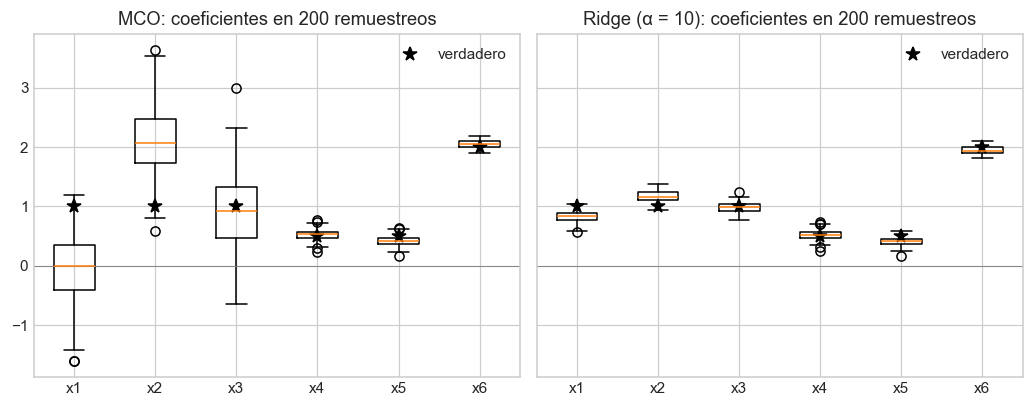

In [9]:
# Diagrama de cajas de los coeficientes bootstrap (MCO frente a Ridge)
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.8), sharey=True)
ax[0].boxplot(coef_ols, labels=nombres_x)
ax[0].set_title("MCO: coeficientes en 200 remuestreos")
ax[1].boxplot(coef_ridge, labels=nombres_x)
ax[1].set_title("Ridge (α = 10): coeficientes en 200 remuestreos")
for a in ax:
    a.plot(range(1, 7), beta_true, "k*", markersize=9, label="verdadero")
    a.axhline(0, color="gray", linewidth=0.6)
    a.legend()
plt.tight_layout()
plt.show()

**Interpretación de resultados:** con **VIF ≈ 100** en x1–x3, **MCO** reparte el efecto común de forma **arbitraria** (desviaciones bootstrap enormes y cambios de signo en la mayoría de los remuestreos) aunque la **suma** de los tres coeficientes se mantiene cerca de 3. **Ridge** los encoge hacia un valor común y **estable**. El **MAE** de ambos en datos nuevos es casi el mismo: **la colinealidad daña la interpretación, no necesariamente la predicción**.

## 4. Fenómeno 2: Lasso Selecciona Variables; Elastic Net Conserva los Pares Correlados

**40 regresores**, de los cuales solo **5** tienen coeficiente distinto de cero. Además, dos de las variables verdaderas (**x1** y **x2**) están **muy correlacionadas** (ρ ≈ 0,95).

In [10]:
# Generador del escenario de selección: 5 variables verdaderas entre 40
n2, p2 = 300, 40
X_sel = rng.normal(size=(n2, p2))
X_sel[:, 1] = 0.95 * X_sel[:, 0] + np.sqrt(1 - 0.95**2) * rng.normal(size=n2)  # x2 ≈ x1
beta_sel = np.zeros(p2)
beta_sel[[0, 1, 2, 3, 4]] = [3, -2, 1.5, 1, -1]
y_sel = X_sel @ beta_sel + rng.normal(scale=1.5, size=n2)
nombres_sel = [f"x{j + 1}" for j in range(p2)]
print("Correlación x1-x2 =", round(np.corrcoef(X_sel[:, 0], X_sel[:, 1])[0, 1], 3))
print("Verdaderos distintos de cero:", {nombres_sel[j]: beta_sel[j] for j in range(5)})

Correlación x1-x2 = 0.948
Verdaderos distintos de cero: {'x1': 3.0, 'x2': -2.0, 'x3': 1.5, 'x4': 1.0, 'x5': -1.0}


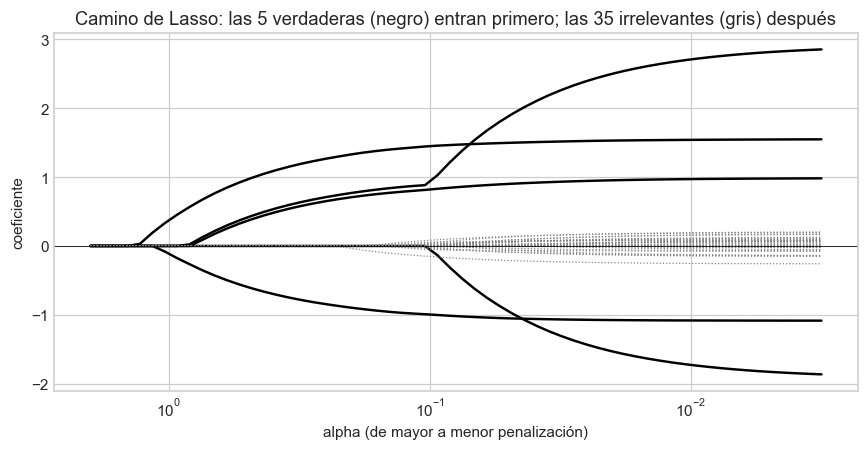

In [11]:
# Camino de coeficientes de Lasso (valores de alpha decrecientes)
alphas_l, coefs_l, _ = lasso_path(X_sel, y_sel, alphas=np.logspace(0.3, -2.5, 60))
plt.figure(figsize=(8, 4.2))
for j in range(p2):
    estilo = "-" if j < 5 else ":"
    color = "black" if j < 5 else "gray"
    plt.plot(alphas_l, coefs_l[j], estilo, color=color, linewidth=1.6 if j < 5 else 0.8)
plt.xscale("log")
plt.gca().invert_xaxis()
plt.axhline(0, color="black", linewidth=0.5)
plt.xlabel("alpha (de mayor a menor penalización)")
plt.ylabel("coeficiente")
plt.title(
    "Camino de Lasso: las 5 verdaderas (negro) entran primero; las 35 irrelevantes "
    "(gris) después"
)
plt.tight_layout()
plt.show()

In [12]:
# Lasso, Ridge y Elastic Net con alpha elegido por validación cruzada (datos i.i.d.: KFold de 5 pliegues)
cv5 = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
busq_lasso = GridSearchCV(
    Lasso(max_iter=20000),
    {"alpha": np.logspace(-2, 0.5, 30)},
    cv=cv5,
    scoring="neg_mean_absolute_error",
).fit(X_sel, y_sel)
busq_ridge = GridSearchCV(
    Ridge(),
    {"alpha": np.logspace(-2, 3, 30)},
    cv=cv5,
    scoring="neg_mean_absolute_error",
).fit(X_sel, y_sel)
busq_enet = GridSearchCV(
    ElasticNet(l1_ratio=0.5, max_iter=20000),
    {"alpha": np.logspace(-2, 0.5, 30)},
    cv=cv5,
    scoring="neg_mean_absolute_error",
).fit(X_sel, y_sel)
ols_sel = LinearRegression().fit(X_sel, y_sel)
tabla_sel = pd.DataFrame(
    {
        "verdadero": beta_sel,
        "MCO": ols_sel.coef_,
        "Ridge": busq_ridge.best_estimator_.coef_,
        "Lasso": busq_lasso.best_estimator_.coef_,
        "ElasticNet": busq_enet.best_estimator_.coef_,
    },
    index=nombres_sel,
)
# Regla de «un error estándar»: el alpha MÁS GRANDE cuyo MAE de validación queda dentro de 1 desviación del mejor (modelo más simple)
res_l = pd.DataFrame(busq_lasso.cv_results_)
umbral = res_l["mean_test_score"].max() - res_l.loc[
    res_l["mean_test_score"].idxmax(), "std_test_score"
] / np.sqrt(5)
alpha_1se = (
    res_l.loc[res_l["mean_test_score"] >= umbral, "param_alpha"].astype(float).max()
)
lasso_1se = Lasso(alpha=alpha_1se, max_iter=20000).fit(X_sel, y_sel)
tabla_sel["Lasso_1se"] = lasso_1se.coef_
print(
    f"alpha óptimo: Lasso = {busq_lasso.best_params_['alpha']:.3f} (regla 1-EE: "
    f"{alpha_1se:.3f}) | Ridge = {busq_ridge.best_params_['alpha']:.2f} | ElasticNet "
    f"= {busq_enet.best_params_['alpha']:.3f}"
)
print(tabla_sel.head(7).round(3))
for m in ["MCO", "Ridge", "Lasso", "Lasso_1se", "ElasticNet"]:
    nz = tabla_sel[m].abs() > 1e-6
    print(
        f"{m:10s}: coeficientes distintos de cero = {int(nz.sum()):2d} | irrelevantes "
        f"conservadas = {int(nz[5:].sum()):2d} | "
        f"máx |coef| irrelevante = {tabla_sel[m][5:].abs().max():.3f}"
    )

alpha óptimo: Lasso = 0.033 (regla 1-EE: 0.073) | Ridge = 0.36 | ElasticNet = 0.015
    verdadero    MCO  Ridge  Lasso  ElasticNet  Lasso_1se
x1        3.0  2.922  2.858  2.223       2.435      1.411
x2       -2.0 -1.927 -1.867 -1.269      -1.467     -0.496
x3        1.5  1.552  1.552  1.512       1.542      1.470
x4        1.0  0.987  0.985  0.931       0.965      0.863
x5       -1.0 -1.087 -1.085 -1.069      -1.074     -1.032
x6        0.0 -0.080 -0.081 -0.069      -0.086     -0.060
x7        0.0  0.208  0.206  0.153       0.187      0.081
MCO       : coeficientes distintos de cero = 40 | irrelevantes conservadas = 35 | máx |coef| irrelevante = 0.261
Ridge     : coeficientes distintos de cero = 40 | irrelevantes conservadas = 35 | máx |coef| irrelevante = 0.260
Lasso     : coeficientes distintos de cero = 29 | irrelevantes conservadas = 24 | máx |coef| irrelevante = 0.227
Lasso_1se : coeficientes distintos de cero = 23 | irrelevantes conservadas = 18 | máx |coef| irrelevante = 0.182


In [13]:
# Error en 300 datos nuevos del mismo generador
X_sel_nuevo = rng.normal(size=(n2, p2))
X_sel_nuevo[:, 1] = 0.95 * X_sel_nuevo[:, 0] + np.sqrt(1 - 0.95**2) * rng.normal(
    size=n2
)
y_sel_nuevo = X_sel_nuevo @ beta_sel + rng.normal(scale=1.5, size=n2)
for nombre, mod in [
    ("MCO", ols_sel),
    ("Ridge", busq_ridge.best_estimator_),
    ("Lasso", busq_lasso.best_estimator_),
    ("Lasso_1se", lasso_1se),
    ("ElasticNet", busq_enet.best_estimator_),
]:
    print(
        f"{nombre:10s}: MAE nuevo = "
        f"{mean_absolute_error(y_sel_nuevo, mod.predict(X_sel_nuevo)):.4f} | R² nuevo "
        f"= {r2_score(y_sel_nuevo, mod.predict(X_sel_nuevo)):.4f}"
    )

MCO       : MAE nuevo = 1.3024 | R² nuevo = 0.6298
Ridge     : MAE nuevo = 1.3031 | R² nuevo = 0.6296
Lasso     : MAE nuevo = 1.2853 | R² nuevo = 0.6385
Lasso_1se : MAE nuevo = 1.3219 | R² nuevo = 0.6179
ElasticNet: MAE nuevo = 1.3031 | R² nuevo = 0.6297


**Interpretación de resultados:** **MCO** y **Ridge** estiman 40 coeficientes y ninguno es exactamente cero: el **ruido** de las 35 variables irrelevantes empeora el error en datos nuevos. **Lasso** con el alpha que minimiza el error de validación anula **11** irrelevantes y es el mejor en datos nuevos (MAE **1,285** frente a **1,302** de MCO); con la **regla de un error estándar** (alpha mayor) anula **17** pero **encoge demasiado** el par correlado (x1 pasa de 3 a **1,41** y x2 de −2 a **−0,50**): la selección se paga con **sesgo**. Las irrelevantes que sobreviven tienen coeficientes pequeños (≤ 0,23) frente a los verdaderos (≥ 1). **Elastic Net** reparte el par correlado de forma más pareja que Lasso (2,44 y −1,47 frente a 2,22 y −1,27). **Moraleja:** Lasso = **selección**; Ridge = **estabilidad**; Elastic Net = **las dos** cuando hay grupos de variables correladas; con ruido alto ninguna recupera la **lista exacta** de variables.

# PARTE III — ¿A Qué Sectores Está Expuesta una Acción? (Mundo 3: datos reales)

**Conjunto de datos:** rendimientos logarítmicos diarios (2019–2026) de **5 acciones** y de **14 factores**: el mercado (**SPY**), los **11 ETF sectoriales** (XLK, XLF, XLE, XLV, XLY, XLP, XLI, XLU, XLB, XLRE, XLC), el **oro** (GLD) y los **bonos** (TLT). **Yahoo Finance**, [https://pypi.org/project/yfinance/](https://pypi.org/project/yfinance/). Los 14 factores están **muy correlacionados** entre sí (todos contienen al mercado).

## 5. Colinealidad Real: VIF de los 14 Factores

In [14]:
# Rendimientos y VIF de los factores
rend = (np.log(precios).diff() * 100).loc["2019-01-01":].dropna(subset=["SPY"])
FACTORES = [
    "SPY",
    "XLK",
    "XLF",
    "XLE",
    "XLV",
    "XLY",
    "XLP",
    "XLI",
    "XLU",
    "XLB",
    "XLRE",
    "XLC",
    "GLD",
    "TLT",
]
ACC = ["AAPL", "JPM", "XOM", "BVN", "KO"]
datos = rend[FACTORES + ACC].dropna()
vif_f = pd.Series(
    [
        variance_inflation_factor(datos[FACTORES].values, j)
        for j in range(len(FACTORES))
    ],
    index=FACTORES,
)
print("Días:", len(datos), "| desde", datos.index.min().date())
print("VIF de cada factor:")
print(vif_f.round(1).sort_values(ascending=False).to_string())
print(
    "Correlación SPY con los sectores:",
    rend[["SPY"] + FACTORES[1:12]].corr().loc["SPY"].drop("SPY").round(2).to_dict(),
)

Días: 1975 | desde 2019-01-02
VIF de cada factor:
SPY     122.0
XLK      28.6
XLI       8.0
XLF       7.6
XLY       7.1
XLB       5.4
XLC       4.9
XLV       3.9
XLRE      3.7
XLP       3.1
XLU       3.0
XLE       2.4
GLD       1.2
TLT       1.2
Correlación SPY con los sectores: {'XLK': 0.92, 'XLF': 0.83, 'XLE': 0.56, 'XLV': 0.74, 'XLY': 0.89, 'XLP': 0.63, 'XLI': 0.87, 'XLU': 0.58, 'XLB': 0.82, 'XLRE': 0.72, 'XLC': 0.85}


In [15]:
# MCO, Ridge, Lasso y Elastic Net para cada acción (alpha por validación cronológica: TimeSeriesSplit)
tscv = TimeSeriesSplit(n_splits=5)


def ajustar(acc):
    X, y = datos[FACTORES], datos[acc]
    mco = make_pipeline(StandardScaler(), LinearRegression()).fit(X, y)
    ridge = GridSearchCV(
        make_pipeline(StandardScaler(), Ridge()),
        {"ridge__alpha": np.logspace(-1, 4, 25)},
        cv=tscv,
    ).fit(X, y)
    lasso = GridSearchCV(
        make_pipeline(StandardScaler(), Lasso(max_iter=20000)),
        {"lasso__alpha": np.logspace(-3, 0, 25)},
        cv=tscv,
    ).fit(X, y)
    enet = GridSearchCV(
        make_pipeline(StandardScaler(), ElasticNet(l1_ratio=0.5, max_iter=20000)),
        {"elasticnet__alpha": np.logspace(-3, 0, 25)},
        cv=tscv,
    ).fit(X, y)
    return (
        pd.DataFrame(
            {
                "MCO": mco[-1].coef_,
                "Ridge": ridge.best_estimator_[-1].coef_,
                "Lasso": lasso.best_estimator_[-1].coef_,
                "ElasticNet": enet.best_estimator_[-1].coef_,
            },
            index=FACTORES,
        ),
        ridge,
        lasso,
        enet,
    )


coef_aapl, r_a, l_a, e_a = ajustar("AAPL")
print(
    "AAPL — coeficientes estandarizados (alpha Ridge =",
    round(r_a.best_params_["ridge__alpha"], 2),
    "| Lasso =",
    round(l_a.best_params_["lasso__alpha"], 4),
    ")",
)
print(coef_aapl.round(3))

AAPL — coeficientes estandarizados (alpha Ridge = 348.07 | Lasso = 0.5623 )
        MCO  Ridge  Lasso  ElasticNet
SPY   0.092  0.342  0.343       0.299
XLK   1.158  0.668  0.562       0.538
XLF   0.014 -0.041  0.000       0.000
XLE   0.050 -0.013  0.000       0.000
XLV   0.064  0.089  0.000       0.007
XLY   0.148  0.192  0.000       0.130
XLP   0.422  0.249  0.000       0.105
XLI  -0.436 -0.148  0.000       0.000
XLU  -0.148 -0.086  0.000       0.000
XLB   0.037 -0.000  0.000       0.000
XLRE  0.079  0.044  0.000       0.000
XLC   0.221  0.263  0.019       0.217
GLD  -0.083 -0.053  0.000      -0.000
TLT   0.005 -0.006 -0.000      -0.000


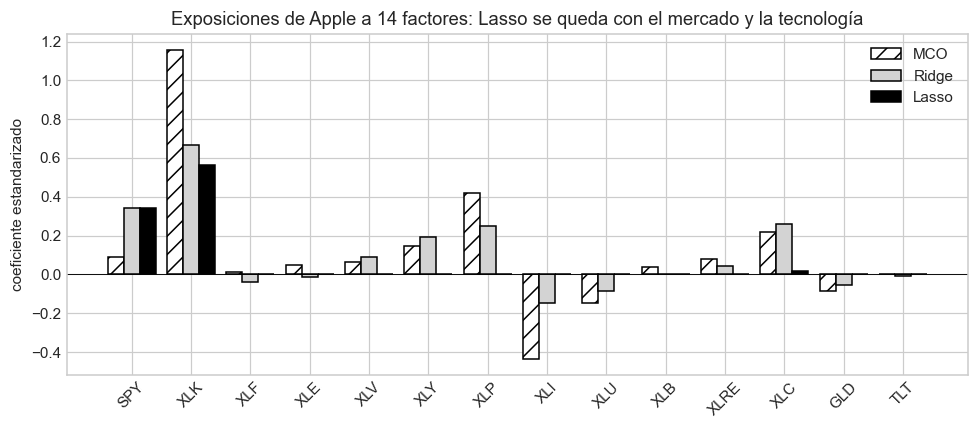

In [16]:
# Gráfico de barras: MCO frente a Ridge y Lasso para AAPL
fig, ax = plt.subplots(figsize=(9, 4))
w = 0.27
xpos = np.arange(len(FACTORES))
ax.bar(
    xpos - w,
    coef_aapl["MCO"],
    w,
    color="white",
    edgecolor="black",
    hatch="//",
    label="MCO",
)
ax.bar(xpos, coef_aapl["Ridge"], w, color="lightgray", edgecolor="black", label="Ridge")
ax.bar(xpos + w, coef_aapl["Lasso"], w, color="black", edgecolor="black", label="Lasso")
ax.set_xticks(xpos)
ax.set_xticklabels(FACTORES, rotation=45)
ax.axhline(0, color="black", linewidth=0.6)
ax.set_ylabel("coeficiente estandarizado")
ax.set_title(
    "Exposiciones de Apple a 14 factores: Lasso se queda con el mercado y la tecnología"
)
ax.legend()
plt.tight_layout()
plt.show()

In [17]:
# Factores que Lasso conserva para cada acción (coeficiente distinto de cero), ordenados por magnitud
resumen = {}
for acc in ACC:
    cf, _, l, _ = ajustar(acc)
    nz = cf["Lasso"][cf["Lasso"].abs() > 1e-4].sort_values(key=np.abs, ascending=False)
    resumen[acc] = ", ".join(f"{k} ({v:+.2f})" for k, v in nz.items())
    print(f"{acc:5s} ({NOMBRES[acc]:20s}): {resumen[acc]}")

AAPL  (Apple               ): XLK (+0.56), SPY (+0.34), XLC (+0.02)


JPM   (JPMorgan            ): XLF (+1.85), XLP (-0.12), XLC (-0.07), TLT (-0.05), XLRE (-0.05), XLV (-0.05), XLY (-0.04)


XOM   (ExxonMobil          ): XLE (+1.88), XLP (+0.14), XLF (-0.09), XLK (-0.07), XLRE (-0.05), XLI (-0.05), TLT (-0.05), XLY (-0.04), XLU (+0.01)


BVN   (Buenaventura (Perú) ): GLD (+1.27), XLB (+0.54), XLE (+0.25)


KO    (Coca-Cola           ): XLP (+0.88), XLK (-0.09), XLY (-0.09), XLRE (+0.09), XLU (+0.08), XLF (+0.05), XLE (+0.05), XLI (+0.04), TLT (-0.02), GLD (-0.01)


**Interpretación de resultados:** los **VIF** de los sectores reales son **altos** (el mercado está dentro de cada ETF). **MCO** produce coeficientes grandes de **signos opuestos** entre SPY y los sectores (se compensan entre sí); **Ridge** los **reparte** de forma más suave; **Lasso** deja solo lo esencial: **Apple → mercado + tecnología (XLK)**, **JPMorgan → finanzas (XLF)**, **ExxonMobil → energía (XLE)**, **Buenaventura → oro (GLD) + materiales (XLB)**, **Coca-Cola → consumo básico (XLP)**. El modelo **disperso** de Lasso es el que un **gestor** puede explicar: «esta acción es, sobre todo, una apuesta por su sector».

# PARTE IV — Pronóstico de la Volatilidad de SPY con 65 Variables (Mundo 3: señal real)

**Objetivo:** la **volatilidad realizada** de los próximos **5 días** de SPY (desviación estándar de los retornos de t+1 a t+5). **Regresores (solo pasado):** retornos rezagados, volatilidades a 1, 5, 22 y 66 días (estilo **HAR**), el **VIX** y su variación, la **volatilidad de Parkinson** (rango máximo–mínimo del día) y el cambio de **volumen**; más sus **cuadrados e interacciones** (grado 2) para llegar a **65 variables**. División **cronológica** 70/30 y `TimeSeriesSplit` con **gap = 5** (el objetivo mira 5 días adelante).

## 6. Construcción de las Variables y del Objetivo

In [18]:
# Variables causales y objetivo futuro (volatilidad realizada de t+1..t+5)
r = (np.log(spy["Close"]).diff() * 100).loc["2012-01-01":]
vix = precios["^VIX"].reindex(r.index).ffill()
base = pd.DataFrame(
    {
        "ret_t": r,
        "ret_t1": r.shift(1),
        "abs_ret": r.abs(),
        "vol_5": r.rolling(5).std(),
        "vol_22": r.rolling(22).std(),
        "vol_66": r.rolling(66).std(),
        "vix": vix,
        "d_vix": vix.diff(),
        "parkinson": (
            np.log(spy["High"] / spy["Low"]).loc[r.index] / np.sqrt(4 * np.log(2)) * 100
        ),
    }
)
base["d_volumen"] = np.log(spy["Volume"]).diff().loc[r.index]
base["objetivo"] = r.shift(-5).rolling(5).std()  # desviación de los 5 retornos futuros
base = base.replace([np.inf, -np.inf], np.nan).dropna()
BASICAS = [c for c in base.columns if c != "objetivo"]
corte = int(len(base) * 0.7)
ent, pru = base.iloc[:corte], base.iloc[corte:]
print("Variables básicas:", len(BASICAS), BASICAS)
print(
    "Entrenamiento:",
    len(ent),
    "días hasta",
    ent.index.max().date(),
    "| Prueba:",
    len(pru),
    "días desde",
    pru.index.min().date(),
)
print(
    f"Objetivo (vol 5 días): media = {base['objetivo'].mean():.3f} | mediana = "
    f"{base['objetivo'].median():.3f} | máx = {base['objetivo'].max():.3f}"
)

Variables básicas: 10 ['ret_t', 'ret_t1', 'abs_ret', 'vol_5', 'vol_22', 'vol_66', 'vix', 'd_vix', 'parkinson', 'd_volumen']
Entrenamiento: 2566 días hasta 2022-06-15 | Prueba: 1101 días desde 2022-06-16
Objetivo (vol 5 días): media = 0.835 | mediana = 0.686 | máx = 8.966


In [19]:
# Expansión polinómica de grado 2 (cuadrados e interacciones) -> 65 variables candidatas
poly = PolynomialFeatures(degree=2, include_bias=False)
poly.fit(ent[BASICAS])
nombres_poly = poly.get_feature_names_out(BASICAS)
print("Número de variables tras la expansión:", len(nombres_poly))
print("Ejemplos:", list(nombres_poly[:4]), "...", list(nombres_poly[-3:]))

Número de variables tras la expansión: 65
Ejemplos: ['ret_t', 'ret_t1', 'abs_ret', 'vol_5'] ... ['parkinson^2', 'parkinson d_volumen', 'd_volumen^2']


## 7. MCO frente a Ridge, Lasso y Elastic Net con Validación Cronológica

In [20]:
# Referencias ingenuas: la volatilidad de hoy (vol_5) y la media del entrenamiento
y_ent, y_pru = ent["objetivo"], pru["objetivo"]
print(
    "Referencia 'persistencia' (vol_5 de hoy): MAE prueba = "
    f"{mean_absolute_error(y_pru, pru['vol_5']):.4f} | R² = "
    f"{r2_score(y_pru, pru['vol_5']):.4f}"
)
print(
    "Referencia 'media de entrenamiento':       MAE prueba = "
    f"{mean_absolute_error(y_pru, np.full(len(pru), y_ent.mean())):.4f} | R² = "
    f"{r2_score(y_pru, np.full(len(pru), y_ent.mean())):.4f}"
)

Referencia 'persistencia' (vol_5 de hoy): MAE prueba = 0.3907 | R² = -0.1657
Referencia 'media de entrenamiento':       MAE prueba = 0.3536 | R² = -0.0097


In [21]:
# Cuatro modelos lineales sobre las 65 variables; alpha elegido con TimeSeriesSplit(gap = 5) SOLO en entrenamiento
tscv5 = TimeSeriesSplit(n_splits=5, gap=5)


def canal(modelo):
    return Pipeline(
        [
            ("poly", PolynomialFeatures(degree=2, include_bias=False)),
            ("esc", StandardScaler()),
            ("mod", modelo),
        ]
    )


rejillas = {
    "MCO": (canal(LinearRegression()), {}),
    "Ridge": (canal(Ridge()), {"mod__alpha": np.logspace(-1, 4, 30)}),
    "Lasso": (canal(Lasso(max_iter=50000)), {"mod__alpha": np.logspace(-3.5, 0, 30)}),
    "ElasticNet": (
        canal(ElasticNet(l1_ratio=0.5, max_iter=50000)),
        {"mod__alpha": np.logspace(-3.5, 0, 30)},
    ),
}
ajustes, filas = {}, []
for nombre, (pipe, rejilla) in rejillas.items():
    bus = GridSearchCV(pipe, rejilla, cv=tscv5, scoring="neg_mean_absolute_error").fit(
        ent[BASICAS], y_ent
    )
    ajustes[nombre] = bus.best_estimator_
    p_ent, p_pru = bus.predict(ent[BASICAS]), bus.predict(pru[BASICAS])
    coefs = bus.best_estimator_["mod"].coef_
    filas.append(
        [
            nombre,
            bus.best_params_.get("mod__alpha", 0),
            int((np.abs(coefs) > 1e-6).sum()),
            r2_score(y_ent, p_ent),
            r2_score(y_pru, p_pru),
            mean_absolute_error(y_pru, p_pru),
            -bus.best_score_,
        ]
    )
tabla_vol = pd.DataFrame(
    filas,
    columns=[
        "modelo",
        "alpha",
        "coef_no_nulos",
        "R2_entren",
        "R2_prueba",
        "MAE_prueba",
        "MAE_cv_entren",
    ],
)
print(tabla_vol.round(4).to_string(index=False))

    modelo    alpha  coef_no_nulos  R2_entren  R2_prueba  MAE_prueba  MAE_cv_entren
       MCO   0.0000             65     0.6297     0.2505      0.3081         0.4304
     Ridge 621.0169             65     0.5775     0.3604      0.2882         0.3372
     Lasso   0.0356             11     0.5608     0.3608      0.2877         0.3274
ElasticNet   0.0621             12     0.5615     0.3638      0.2866         0.3262


In [22]:
# Las variables que Lasso conserva, ordenadas por |coeficiente estandarizado|
coef_lasso = pd.Series(ajustes["Lasso"]["mod"].coef_, index=nombres_poly)
top = coef_lasso[coef_lasso.abs() > 1e-6].sort_values(key=np.abs, ascending=False)
print("Variables conservadas por Lasso:", len(top))
print(top.head(12).round(4).to_string())

Variables conservadas por Lasso: 11
vix               0.2933
vol_5             0.0725
parkinson         0.0631
ret_t1 abs_ret   -0.0431
ret_t1^2          0.0368
vol_5 vix         0.0245
ret_t            -0.0241
abs_ret vix       0.0177
ret_t^2           0.0080
ret_t vix        -0.0061
abs_ret^2         0.0031


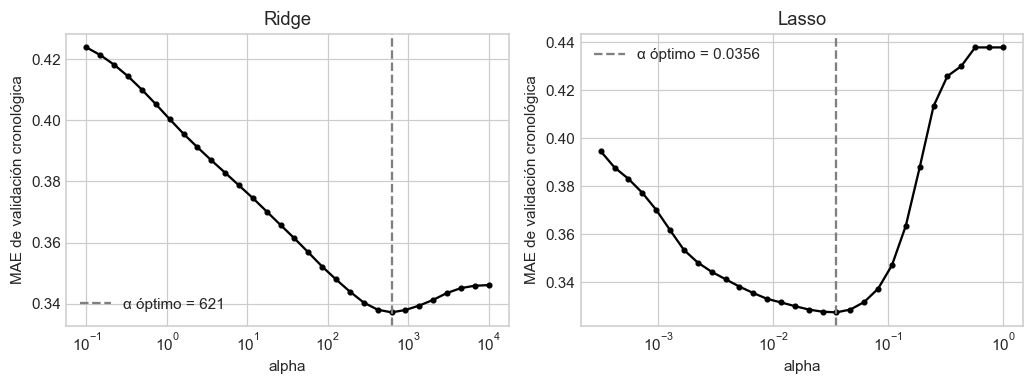

In [23]:
# Curva de validación de Ridge y Lasso: MAE de validación cronológica frente a alpha
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.6))
for k, nombre in enumerate(["Ridge", "Lasso"]):
    pipe, rejilla = rejillas[nombre]
    bus = GridSearchCV(pipe, rejilla, cv=tscv5, scoring="neg_mean_absolute_error").fit(
        ent[BASICAS], y_ent
    )
    ax[k].plot(
        rejilla["mod__alpha"],
        -bus.cv_results_["mean_test_score"],
        "o-",
        color="black",
        markersize=3,
    )
    ax[k].axvline(
        bus.best_params_["mod__alpha"],
        color="gray",
        linestyle="--",
        label=f"α óptimo = {bus.best_params_['mod__alpha']:.3g}",
    )
    ax[k].set_xscale("log")
    ax[k].set_xlabel("alpha")
    ax[k].set_ylabel("MAE de validación cronológica")
    ax[k].set_title(nombre)
    ax[k].legend()
plt.tight_layout()
plt.show()

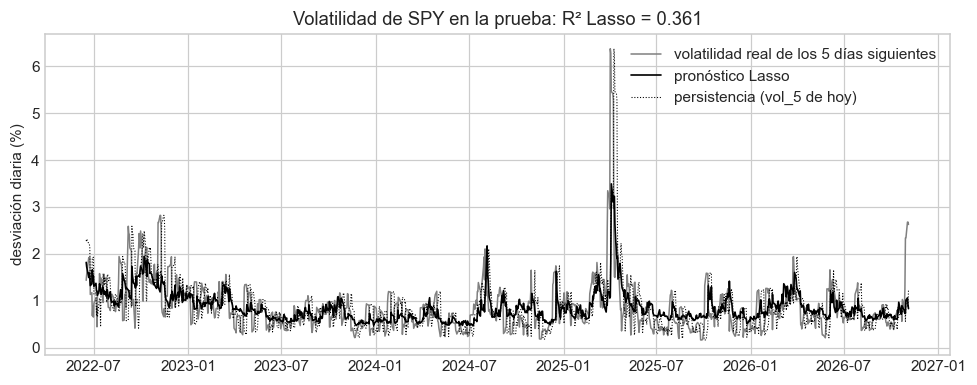

In [24]:
# Volatilidad real y pronosticada (Lasso) en la prueba
p_lasso = ajustes["Lasso"].predict(pru[BASICAS])
plt.figure(figsize=(9, 3.6))
plt.plot(
    pru.index,
    y_pru.values,
    color="gray",
    linewidth=1,
    label="volatilidad real de los 5 días siguientes",
)
plt.plot(pru.index, p_lasso, color="black", linewidth=1.1, label="pronóstico Lasso")
plt.plot(
    pru.index,
    pru["vol_5"].values,
    color="black",
    linewidth=0.7,
    linestyle=":",
    label="persistencia (vol_5 de hoy)",
)
plt.ylabel("desviación diaria (%)")
plt.legend()
plt.title(f"Volatilidad de SPY en la prueba: R² Lasso = {r2_score(y_pru, p_lasso):.3f}")
plt.tight_layout()
plt.show()

**Interpretación de resultados:** con **65 variables**, **MCO** tiene el mejor **R² de entrenamiento** pero el peor de **prueba**: **sobreajusta**. **Ridge**, **Lasso** y **Elastic Net** sacrifican ajuste en entrenamiento y **ganan en prueba**, superando a la **persistencia** (repetir la volatilidad de hoy). **Lasso** conserva solo **11 de las 65** variables, dominadas por el **VIX**, **vol_5** y la **volatilidad de Parkinson**; la **persistencia** (repetir la volatilidad de hoy) tiene **R² negativo**: es peor que la media. **Moraleja:** cuando hay **muchas variables** y **pocas señales**, la regularización es la diferencia entre **memorizar** y **generalizar**.

**Advertencia de fuga de datos:** `PolynomialFeatures` y `StandardScaler` van **dentro** del `Pipeline`, así que se ajustan solo con el pliegue de entrenamiento de cada iteración de `TimeSeriesSplit`; el **gap = 5** evita que un día de entrenamiento comparta sus 5 retornos futuros con el pliegue de validación.

## 8. Actividad Autónoma

1. Repita la Parte III con **MSFT**, **CAT** y **SCCO**. ¿Qué factores conserva Lasso para la minera de cobre? ¿Aparece el oro?
2. En la Parte IV cambie el objetivo a la volatilidad de los próximos **22 días** (un mes) con `gap = 22`. ¿Mejora o empeora el R² de prueba? ¿Por qué?
3. Pruebe `l1_ratio` de **0,2** y **0,8** en Elastic Net y reporte cuántas variables conserva cada uno.

**Entregable:** notebook ejecutado con la tabla de exposiciones de las 3 acciones nuevas y un párrafo (≤ 150 palabras) sobre cuándo preferiría Ridge, Lasso o Elastic Net en un sistema de riesgo.